# Day 1 — Build your first predictive model

## Step 0: Load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statannotations.Annotator import Annotator


In [2]:
df = pd.read_csv("../data/raw/diabetic_data.csv",
                 keep_default_na=False,
                 na_values=["?"],
                 dtype={"payer_code": "str"})

## replace '?" with NA
#df = df.replace("?", pd.NA)

In [3]:
str_cols = df.select_dtypes(include=['str']).columns
str_cols = str_cols[ ~str_cols.isin( ['age', 'weight' ] ) ]
df[str_cols] = df[str_cols].astype('category')

In [4]:
## now set the order of some of the variables
age_order = [  '[0-10)',  '[10-20)',  '[20-30)',  '[30-40)',  '[40-50)',  '[50-60)',
  '[60-70)',  '[70-80)',  '[80-90)', '[90-100)']

age_type = pd.CategoricalDtype( categories=age_order,
                                ordered=True )
df["age"] = df["age"].astype(age_type)

weight_order = [ "[0-25)", "[25-50)", "[50-75)", "[75-100)",
                 "[100-125)", "[125-150)", "[150-175)",
                 "[175-200)", ">200" ]
weight_type = pd.CategoricalDtype( categories=weight_order,
                                   ordered=True )
df["weight"] = df["weight"].astype(weight_type)

In [5]:
# Returns an Index of column names containing '_id'
id_cols = df.columns[df.columns.str.contains('_id')]
id_cols = id_cols[ ~id_cols.isin( ["encounter_id"] ) ]
id_cols
df[ id_cols ] = df[ id_cols ].astype('category')

In [6]:
cat_cols = id_cols.append( str_cols )

## Day 5: Prepare the modeling dataset

In [7]:
df[ "readmit_30_label" ] = [ "Early" if x == "<30" else "Later" for x in df[ "readmitted" ] ]
labels = df[ "readmit_30_label" ]
##X = df.drop(columns=["readmit_30_02", "readmit_30", "readmitted", "patient_nbr", "encounter_id"])
features_to_model = "num_procedures number_outpatient number_emergency number_inpatient A1Cresult metformin discharge_disposition_id diabetesMed admission_source_id admission_type_id max_glu_serum repaglinide glipizide insulin".split()
X = df[ features_to_model ]

## Repeat the LogisticRegression, using the updated set of features (now including insulin, glipizide, and repaglinide)

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SelectPercentile, chi2
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import make_column_selector as selector

numeric_transformer = Pipeline(
    steps=[("imputer", SimpleImputer(strategy="median")), 
           ("scaler", StandardScaler())]
)

categorical_transformer = Pipeline(
    steps=[
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=True)),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, selector(dtype_include=np.number)),
        ("cat", categorical_transformer, selector(dtype_include="category")),
    ]
)


In [9]:
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.base import clone

groups = df["patient_nbr"]

# -------------------------------------------------
# 1. Reserve approximately 20% for final testing
# -------------------------------------------------

outer_cv = StratifiedGroupKFold(
    n_splits=5, 
    shuffle=True, 
    random_state=42
)

outer_cv = StratifiedGroupKFold( n_splits=5, 
                                 shuffle=True, 
                                 random_state=42 )


train_idx, test_idx = next(outer_cv.split(X, labels, groups))

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = labels.iloc[train_idx]
y_test = labels.iloc[test_idx]

train_groups = groups.iloc[train_idx]


# -------------------------------------------------
# 2. Define the model and preprocessing pipeline
# -------------------------------------------------

clf = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression( solver="saga",
                                       max_iter=5000,
                                       tol=1e-3,
                                       random_state=42 ) )
])


# -------------------------------------------------
# 3. Define which hyperparameters to evaluate
# -------------------------------------------------

param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10],
    "classifier__l1_ratio":  np.linspace(0, 1, 11)
}


# -------------------------------------------------
# 4. Perform CV and select the best hyperparameters
# -------------------------------------------------

inner_cv = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=123
)

grid = GridSearchCV(
    estimator=clf,
    param_grid=param_grid,
    cv=inner_cv,
    scoring="roc_auc",
    refit=True,
    verbose=3,
    n_jobs=10 
)

grid.fit(X_train, y_train, groups=train_groups)


# -------------------------------------------------
# 5. Retrieve the selected configuration
# -------------------------------------------------

print(grid.best_params_)
print(grid.best_score_)

final_clf = grid.best_estimator_


# -------------------------------------------------
# 6. Evaluate on the untouched 20% test set
# -------------------------------------------------

test_probabilities = final_clf.predict_proba(X_test)[:, 1]

test_auc = roc_auc_score(y_test, test_probabilities)

print("Test AUC:", test_auc)



Fitting 5 folds for each of 44 candidates, totalling 220 fits
{'classifier__C': 0.1, 'classifier__l1_ratio': np.float64(0.0)}
0.6623926957360846
Test AUC: 0.6629737465552079


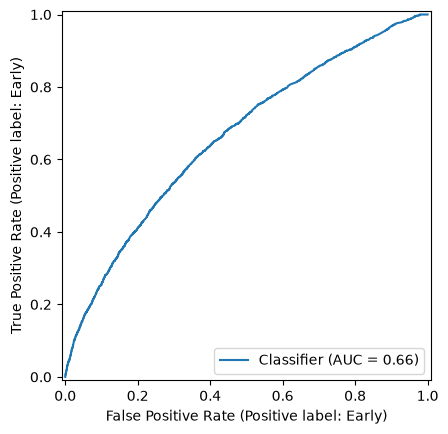

In [10]:
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

pos_idx = list(final_clf.classes_).index("Early")
y_score = final_clf.predict_proba(X_test)[:, pos_idx]
RocCurveDisplay.from_predictions(y_test, y_score, pos_label="Early")
plt.show()

In [11]:
from sklearn.metrics import classification_report
print( classification_report( y_test, final_clf.predict( X_test ) ) )

              precision    recall  f1-score   support

       Early       0.41      0.01      0.02      2272
       Later       0.89      1.00      0.94     18082

    accuracy                           0.89     20354
   macro avg       0.65      0.50      0.48     20354
weighted avg       0.84      0.89      0.84     20354



In [12]:
from sklearn.metrics import average_precision_score
pos_idx = list(final_clf.classes_).index("Early")
y_score = final_clf.predict_proba(X_test)[:, pos_idx]

average_precision_score( y_test, y_score, pos_label='Early' )

0.20945655763752163

## Day 4 — Compare logistic regression with a tree-based model

In [13]:
final_lr_clf = final_clf

In [14]:
model = final_lr_clf[ 'classifier' ]
raw_coefficients = model.coef_
raw_intercept = model.intercept_

# 2. Map features to coefficients for a clean overview
#coef_df = pd.DataFrame({
#    'Feature': X_train.columns,
#    'Coefficient': model.coef_[0]  # Use [0] for binary classification
#})

#print(coef_df)

In [15]:
# 1. Extract the feature names from your preprocessor or pipeline
# (Assuming 'preprocessor' is the ColumnTransformer step inside your model pipeline)
feature_names = final_lr_clf.named_steps['preprocessor'].get_feature_names_out()

# 2. Get the coefficients from your final model step
coefficients = final_lr_clf.named_steps['classifier'].coef_[0] # Use coef_ for 1D or coef_[0] depending on shape

# 3. Combine them into a readable pandas DataFrame or dictionary
import pandas as pd
coef_mapping = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
}).sort_values(by='Coefficient', ascending=False)

print(coef_mapping)


                             Feature  Coefficient
22  cat__discharge_disposition_id_11     2.027609
24  cat__discharge_disposition_id_13     0.657061
38               cat__diabetesMed_No     0.457364
25  cat__discharge_disposition_id_14     0.440382
33  cat__discharge_disposition_id_23     0.414471
..                               ...          ...
26  cat__discharge_disposition_id_15    -0.330365
3              num__number_inpatient    -0.345155
16   cat__discharge_disposition_id_5    -0.670924
37  cat__discharge_disposition_id_28    -0.899816
32  cat__discharge_disposition_id_22    -1.023825

[80 rows x 2 columns]


In [16]:
np.median( abs( coefficients ) )

np.float64(0.14033107479248647)

In [17]:
cuts = np.linspace(0.4, 1, 13)
quantiles=np.quantile( abs( coefficients ), cuts )
pd.DataFrame( { 'cuts':cuts, 'quantiles':quantiles } )

,cuts,quantiles
0,0.40,0.095619
1,0.45,0.112658
2,0.50,0.140331
3,0.55,0.158339
4,0.60,0.173856
5,0.65,0.205667
6,0.70,0.239597
7,0.75,0.291012
8,0.80,0.307275
9,0.85,0.332583


In [18]:
##coef_mapping[ abs( coef_mapping[ "Coefficient" ] ) >= np.median( abs( coefficients ) ) ]
coef_mapping[ abs( coef_mapping[ "Coefficient" ] ) >= 0.0077 ]

,Feature,Coefficient
22,cat__discharge_disposition_id_11,2.027609
24,cat__discharge_disposition_id_13,0.657061
38,cat__diabetesMed_No,0.457364
25,cat__discharge_disposition_id_14,0.440382
33,cat__discharge_disposition_id_23,0.414471
...,...,...
26,cat__discharge_disposition_id_15,-0.330365
3,num__number_inpatient,-0.345155
16,cat__discharge_disposition_id_5,-0.670924
37,cat__discharge_disposition_id_28,-0.899816


### Conclusions:
* Of the reduced feature set that the models were trained on, it's clear that the discharge_disposition was the most predictive

In [19]:
from sklearn.inspection import permutation_importance

result = permutation_importance(
    final_lr_clf,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
)

In [20]:
pd.DataFrame( {
    "features":X_train.columns,
    "importances_mean":result.importances_mean,
    "importances_std":result.importances_std } ).sort_values(by='importances_mean', ascending=False)

,features,importances_mean,importances_std
3,number_inpatient,0.070521,0.004872
6,discharge_disposition_id,0.067797,0.003115
5,metformin,0.003494,0.000942
9,admission_type_id,0.003317,0.001285
8,admission_source_id,0.002086,0.000677
4,A1Cresult,0.001733,0.000755
13,insulin,0.001695,0.000815
7,diabetesMed,0.001680,0.001114
2,number_emergency,0.001246,0.000177
12,glipizide,0.001068,0.000279


### Conclusion: 
* **Both coefficients and `permutation_importance()` indicate that `discharge_disposition_id`, `number_inpatient`, `metformin` and `diabetesMed` have the most predictive power of the features that were provided.**

### visualize the skewness of the numerical features

In [21]:
X.columns

Index(['num_procedures', 'number_outpatient', 'number_emergency',
       'number_inpatient', 'A1Cresult', 'metformin',
       'discharge_disposition_id', 'diabetesMed', 'admission_source_id',
       'admission_type_id', 'max_glu_serum', 'repaglinide', 'glipizide',
       'insulin'],
      dtype='str')

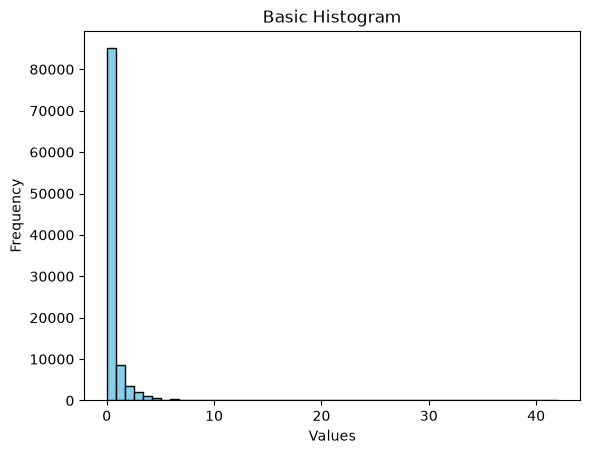

In [22]:
import matplotlib.pyplot as plt

data = X[ 'number_outpatient' ]
# Create the histogram
plt.hist(data, bins=50, color='skyblue', edgecolor='black')

# Add labels and title
plt.xlabel('Values')
plt.ylabel('Frequency')
plt.title('Basic Histogram')

# Display the plot
plt.show()


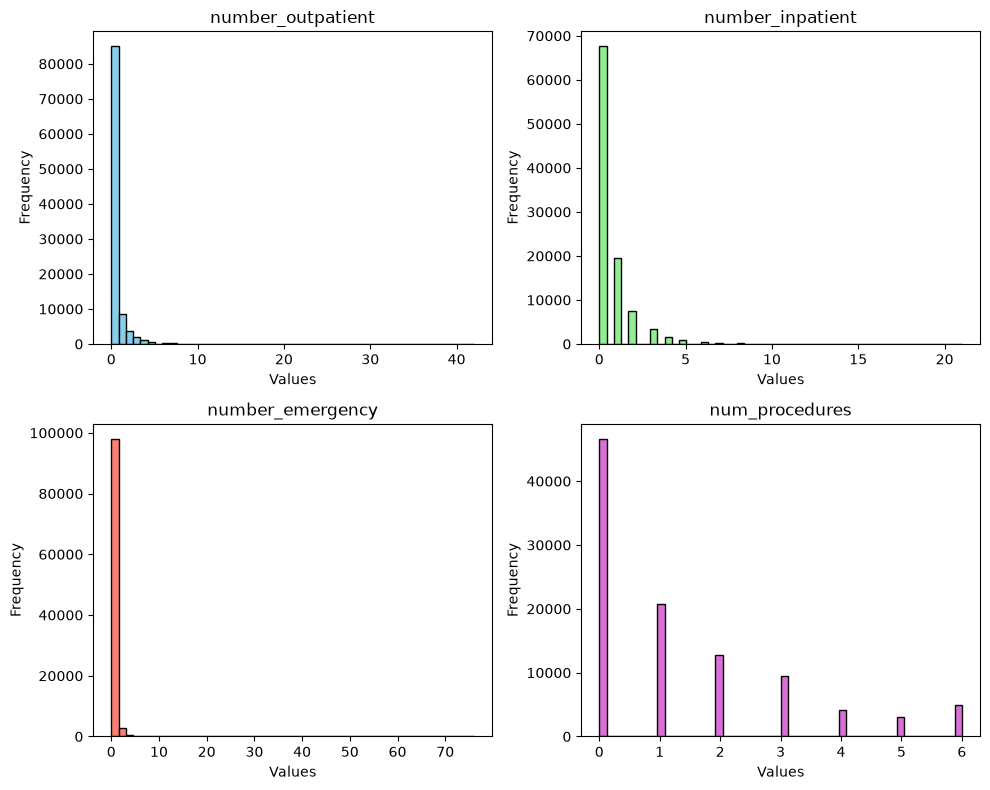

In [23]:
import matplotlib.pyplot as plt
import numpy as np

# Create a 2x2 subplot figure grid
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(10, 8))

# Plot each histogram on its designated axis (row, col)
axes[0, 0].hist( X[ 'number_outpatient' ], bins=50, color='skyblue', edgecolor='black')
axes[0, 0].set_title('number_outpatient')

axes[0, 1].hist(X[ 'number_inpatient' ], bins=50, color='lightgreen', edgecolor='black')
axes[0, 1].set_title('number_inpatient')

axes[1, 0].hist(X[ 'number_emergency' ], bins=50, color='salmon', edgecolor='black')
axes[1, 0].set_title('number_emergency')

axes[1, 1].hist(X[ 'num_procedures' ], bins=50, color='orchid', edgecolor='black')
axes[1, 1].set_title('num_procedures')

# 4. Global configurations
for ax in axes.flat:
    ax.set_xlabel('Values')
    ax.set_ylabel('Frequency')

# Prevents subplot titles and labels from overlapping
plt.tight_layout()

# 5. Render
plt.show()


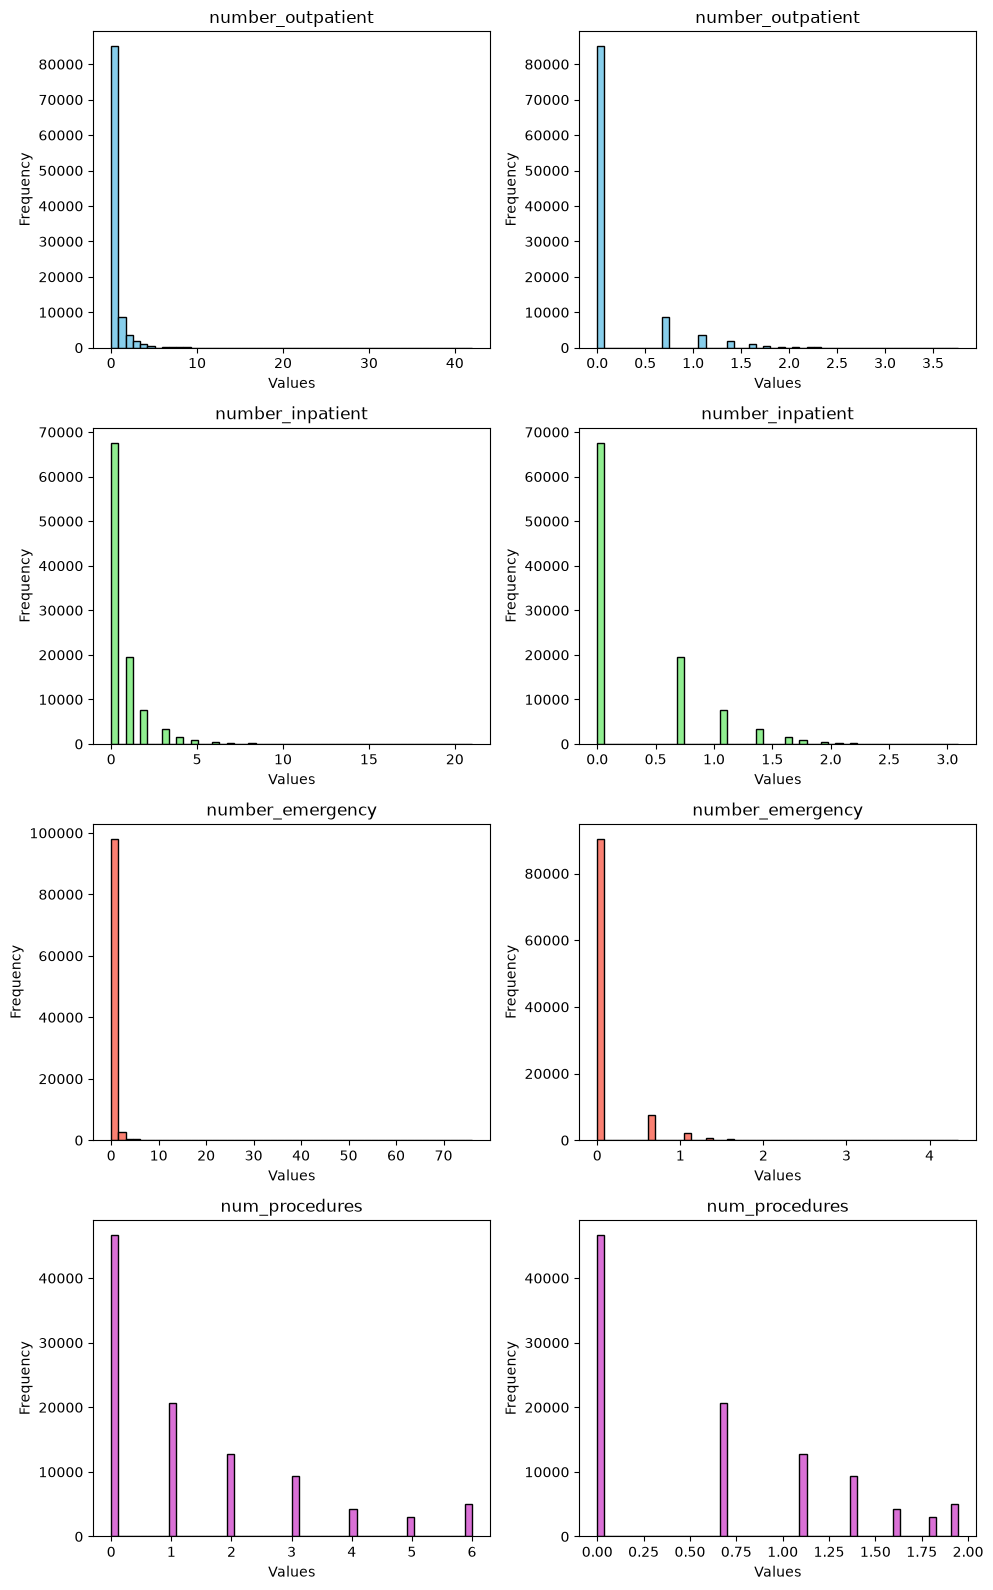

In [24]:
import matplotlib.pyplot as plt
import numpy as np

# Create a 2x2 subplot figure grid
fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(10, 16))

features = ['number_outpatient', 'number_inpatient', 'number_emergency', 'num_procedures' ]
colors = [ 'skyblue', 'lightgreen', 'salmon', 'orchid' ]

for i in range(4):
    # Plot each histogram on its designated axis (row, col)
    feat=features[i]
    col=colors[i]
    axes[i, 0].hist( X[ feat ], bins=50, color=col, edgecolor='black')
    axes[i, 0].set_title(feat)

    axes[i, 1].hist( np.log1p(X[ feat ]), bins=50, color=col, edgecolor='black')
    axes[i, 1].set_title(feat)


# 4. Global configurations
for ax in axes.flat:
    ax.set_xlabel('Values')
    ax.set_ylabel('Frequency')

# Prevents subplot titles and labels from overlapping
plt.tight_layout()

# 5. Render
plt.show()


#### Let's apply the suggested transformer

In [25]:
from sklearn.preprocessing import FunctionTransformer, StandardScaler

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log", FunctionTransformer(np.log1p)),
    ("scaler", StandardScaler()),
])

numeric_cols = X.select_dtypes(include=np.number).columns

X_transformed = pd.DataFrame(
    numeric_transformer.fit_transform(X[numeric_cols]),
    columns=numeric_cols,
    index=X.index,
)

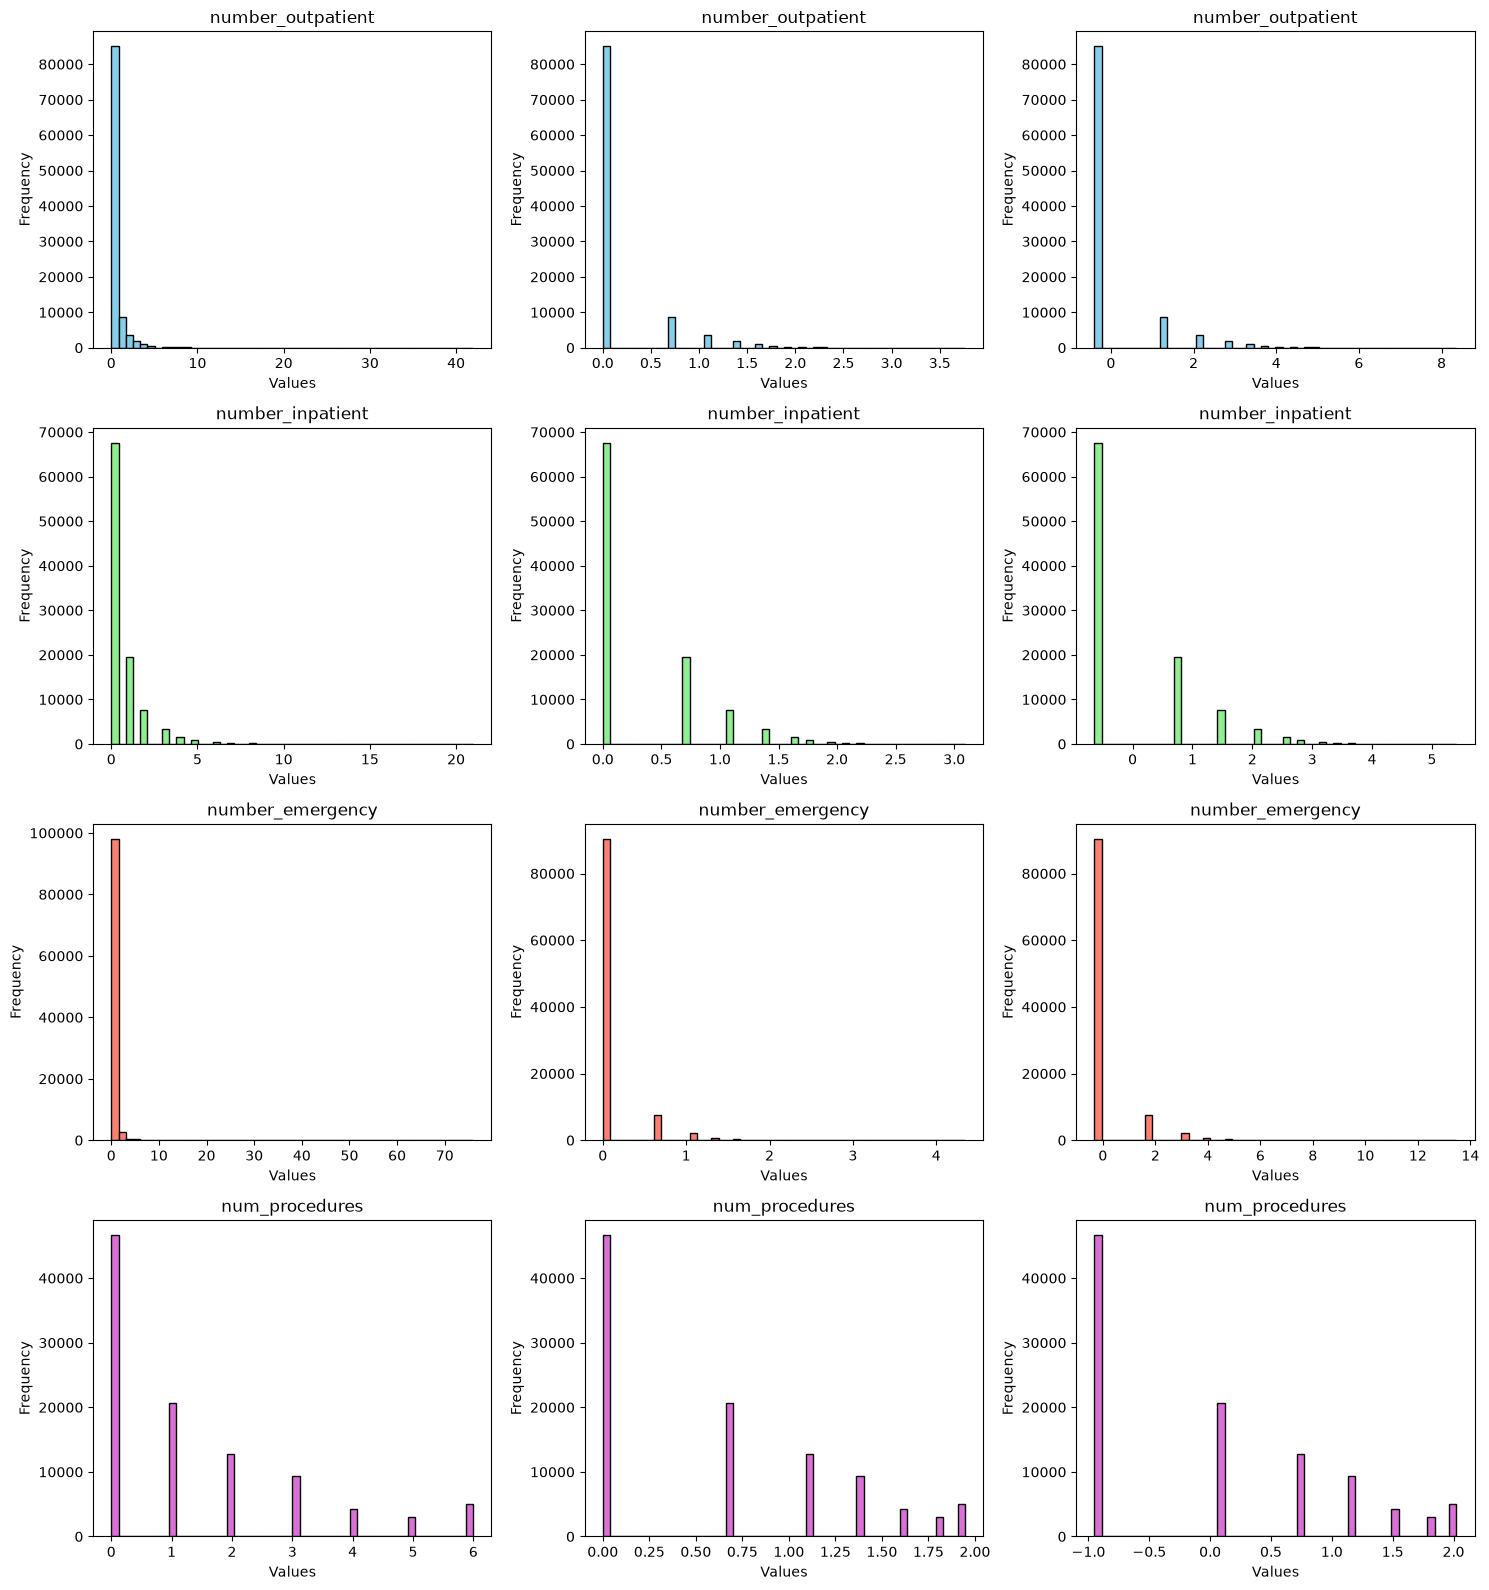

In [26]:
import matplotlib.pyplot as plt
import numpy as np

# Create a 2x2 subplot figure grid
fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(15, 16))

features = ['number_outpatient', 'number_inpatient', 'number_emergency', 'num_procedures' ]
colors = [ 'skyblue', 'lightgreen', 'salmon', 'orchid' ]

for i in range(4):
    # Plot each histogram on its designated axis (row, col)
    feat=features[i]
    col=colors[i]
    axes[i, 0].hist( X[ feat ], bins=50, color=col, edgecolor='black')
    axes[i, 0].set_title(feat)

    axes[i, 1].hist( np.log1p(X[ feat ]), bins=50, color=col, edgecolor='black')
    axes[i, 1].set_title(feat)

    axes[i, 2].hist( X_transformed[ feat ], bins=50, color=col, edgecolor='black')
    axes[i, 2].set_title(feat)


# 4. Global configurations
for ax in axes.flat:
    ax.set_xlabel('Values')
    ax.set_ylabel('Frequency')

# Prevents subplot titles and labels from overlapping
plt.tight_layout()

# 5. Render
plt.show()


In [27]:
numeric_transformer = Pipeline(
    steps=[("imputer", SimpleImputer(strategy="median")), 
           ("scaler", StandardScaler())]
)

categorical_transformer = Pipeline(
    steps=[
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, selector(dtype_include=np.number)),
        ("cat", categorical_transformer, selector(dtype_include="category")),
    ]
)

numeric_log_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log", FunctionTransformer(np.log1p)),
    ("scaler", StandardScaler()),
])


log_preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_log_transformer, selector(dtype_include=np.number)),
        ("cat", categorical_transformer, selector(dtype_include="category")),
    ]
)



In [28]:
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.base import clone

groups = df["patient_nbr"]

# -------------------------------------------------
# 1. Reserve approximately 20% for final testing
# -------------------------------------------------

outer_cv = StratifiedGroupKFold(
    n_splits=5, 
    shuffle=True, 
    random_state=42
)

outer_cv = StratifiedGroupKFold( n_splits=5, 
                                 shuffle=True, 
                                 random_state=42 )


train_idx, test_idx = next(outer_cv.split(X, labels, groups))

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = labels.iloc[train_idx]
y_test = labels.iloc[test_idx]

train_groups = groups.iloc[train_idx]

In [29]:
clf = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression( solver="saga",
                                       max_iter=5000,
                                       tol=1e-3,
                                       random_state=42 ) )
])

log_clf = Pipeline([
    ("preprocessor", clone(log_preprocessor)),
    ("classifier", LogisticRegression( solver="saga",
                                       max_iter=5000,
                                       tol=1e-3,
                                       random_state=42 ) )
])


#### Test the impact of different pre-processing steps

In [30]:
clf.fit(X_train, y_train)
print("model score: %.3f" % clf.score(X_test, y_test))

model score: 0.888


In [31]:
log_clf.fit(X_train, y_train)
print("model score: %.3f" % log_clf.score(X_test, y_test))

model score: 0.888


In [32]:
from sklearn.metrics import classification_report
print( classification_report( y_test, clf.predict( X_test ) ) )

              precision    recall  f1-score   support

       Early       0.41      0.01      0.02      2272
       Later       0.89      1.00      0.94     18082

    accuracy                           0.89     20354
   macro avg       0.65      0.51      0.48     20354
weighted avg       0.84      0.89      0.84     20354



In [33]:
from sklearn.metrics import classification_report
print( classification_report( y_test, log_clf.predict( X_test ) ) )

              precision    recall  f1-score   support

       Early       0.33      0.00      0.01      2272
       Later       0.89      1.00      0.94     18082

    accuracy                           0.89     20354
   macro avg       0.61      0.50      0.47     20354
weighted avg       0.83      0.89      0.84     20354



In [34]:
from sklearn.metrics import roc_auc_score
pos_idx = list(log_clf.classes_).index("Early")
y_score = clf.predict_proba(X_test)[:, pos_idx]

roc_auc_score(y_test == "Early", y_score)

0.6632693969646883

In [35]:
from sklearn.metrics import roc_auc_score
pos_idx = list(clf.classes_).index("Early")
y_score = clf.predict_proba(X_test)[:, pos_idx]

roc_auc_score(y_test == "Early", y_score)

0.6632693969646883

In [36]:
X14=X
X14_train=X_train
X14_test=X_test

## Evaluate Feature Selection Using the full feature set, excluding patient_nbr and a few others

In [37]:
df.columns

Index(['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'time_in_hospital', 'payer_code', 'medical_specialty',
       'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1',
       'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult',
       'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
       'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted',
       'readmit_30_label'],
      dtype='str')

In [38]:
drop_cols = [ 'encounter_id', 'patient_nbr', 'payer_code', 'medical_specialty', 'readmitted', 'weight', 'readmit_30_label' ]

X = df[ df.columns[~df.columns.isin( drop_cols ) ] ]
y = df[ "readmit_30_label" ]

In [39]:
numeric_transformer = Pipeline(
    steps=[("imputer", SimpleImputer(strategy="median")), 
           ("scaler", StandardScaler())]
)

categorical_transformer = Pipeline(
    steps=[
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=True)),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, selector(dtype_include=np.number)),
        ("cat", categorical_transformer, selector(dtype_include="category")),
    ]
)


### re-run the logisticRegression on the (mostly) full set of features
#### Rationale: to determine if there are any combinatorial relationships that were excluded by using the reduced set

In [40]:
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.base import clone

groups = df["patient_nbr"]

# -------------------------------------------------
# 1. Reserve approximately 20% for final testing
# -------------------------------------------------

outer_cv = StratifiedGroupKFold(
    n_splits=5, 
    shuffle=True, 
    random_state=42
)

outer_cv = StratifiedGroupKFold( n_splits=5, 
                                 shuffle=True, 
                                 random_state=42 )


train_idx, test_idx = next(outer_cv.split(X, labels, groups))

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

train_groups = groups.iloc[train_idx]


In [41]:
X_train.columns

Index(['race', 'gender', 'age', 'admission_type_id',
       'discharge_disposition_id', 'admission_source_id', 'time_in_hospital',
       'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1',
       'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult',
       'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
       'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed'],
      dtype='str')

In [42]:
# -------------------------------------------------
# 2. Define the model and preprocessing pipeline
# -------------------------------------------------

clf = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression( solver="saga",
                                       max_iter=5000,
                                       tol=1e-3,
                                       random_state=42 ) )
])


# -------------------------------------------------
# 3. Define which hyperparameters to evaluate
# -------------------------------------------------

param_grid = {
    "classifier__C": [0.01, 0.1, 1],
    "classifier__l1_ratio": [0.0, 0.5], #np.linspace(0, 1, 11)
}


# -------------------------------------------------
# 4. Perform CV and select the best hyperparameters
# -------------------------------------------------

inner_cv = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=123
)

lr_grid = GridSearchCV(
    estimator=clf,
    param_grid=param_grid,
    cv=inner_cv,
    scoring="roc_auc",
    refit=True,
    verbose=3,
    n_jobs=5 
)

lr_grid.fit(X_train, y_train, groups=train_groups)


# -------------------------------------------------
# 5. Retrieve the selected configuration
# -------------------------------------------------

print(lr_grid.best_params_)
print(lr_grid.best_score_)

final_clf = lr_grid.best_estimator_


# -------------------------------------------------
# 6. Evaluate on the untouched 20% test set
# -------------------------------------------------

test_probabilities = final_clf.predict_proba(X_test)[:, 1]

test_auc = roc_auc_score(y_test, test_probabilities)

print("Test AUC:", test_auc)

[CV 2/5] END classifier__C=0.01, classifier__l1_ratio=0.0;, score=0.663 total time=   1.5s
[CV 1/5] END classifier__C=0.01, classifier__l1_ratio=0.2;, score=0.656 total time=   4.4s
[CV 2/5] END classifier__C=0.01, classifier__l1_ratio=0.4;, score=0.656 total time=   2.2s
[CV 3/5] END classifier__C=0.01, classifier__l1_ratio=0.5;, score=0.650 total time=   3.9s
[CV 4/5] END classifier__C=0.01, classifier__l1_ratio=0.7000000000000001;, score=0.654 total time=   4.4s
[CV 5/5] END classifier__C=0.01, classifier__l1_ratio=0.9;, score=0.642 total time=   4.3s
[CV 2/5] END classifier__C=0.1, classifier__l1_ratio=0.1;, score=0.668 total time=   8.3s
[CV 1/5] END classifier__C=0.1, classifier__l1_ratio=0.30000000000000004;, score=0.663 total time=  12.4s
[CV 2/5] END classifier__C=0.1, classifier__l1_ratio=0.5;, score=0.668 total time=   7.6s
[CV 3/5] END classifier__C=0.1, classifier__l1_ratio=0.6000000000000001;, score=0.660 total time=  12.5s
[CV 3/5] END classifier__C=0.1, classifier__l1_r

In [43]:
# 1. Extract the feature names from your preprocessor or pipeline
# (Assuming 'preprocessor' is the ColumnTransformer step inside your model pipeline)
feature_names = final_clf.named_steps['preprocessor'].get_feature_names_out()

# 2. Get the coefficients from your final model step
coefficients = final_clf.named_steps['classifier'].coef_[0] # Use coef_ for 1D or coef_[0] depending on shape

# 3. Combine them into a readable pandas DataFrame or dictionary
import pandas as pd
coef_mapping = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
}).sort_values(by='Coefficient', ascending=False)

print(coef_mapping)


                               Feature  Coefficient
45    cat__discharge_disposition_id_11     2.182311
47    cat__discharge_disposition_id_13     0.634458
48    cat__discharge_disposition_id_14     0.388139
56    cat__discharge_disposition_id_23     0.345153
394                    cat__diag_1_486     0.277064
...                                ...          ...
2025                   cat__diag_3_785    -0.421719
39     cat__discharge_disposition_id_5    -0.671867
60    cat__discharge_disposition_id_28    -0.935675
55    cat__discharge_disposition_id_22    -0.992001
774                    cat__diag_1_V58    -1.279132

[2350 rows x 2 columns]


In [44]:
coef_mapping[ coef_mapping[ "Feature" ].str.contains( "number" ) ] 

,Feature,Coefficient
4,num__number_outpatient,0.010973
7,num__number_diagnoses,-0.033146
5,num__number_emergency,-0.035434
6,num__number_inpatient,-0.317083


In [45]:
cuts = np.linspace(0.9, 1, 21)
quantiles=np.quantile( abs( coefficients ), cuts )
pd.DataFrame( { 'cuts':cuts, 'quantiles':quantiles } )

,cuts,quantiles
0,0.900,0.009843
1,0.905,0.016313
2,0.910,0.028103
3,0.915,0.033039
4,0.920,0.037528
5,0.925,0.045058
6,0.930,0.052615
7,0.935,0.065386
8,0.940,0.078591
9,0.945,0.090628


In [46]:
##coef_mapping[ abs( coef_mapping[ "Coefficient" ] ) >= np.median( abs( coefficients ) ) ]
coef_mapping[ abs( coef_mapping[ "Coefficient" ] ) >= 0.009843 ][:30]

,Feature,Coefficient
45,cat__discharge_disposition_id_11,2.182311
47,cat__discharge_disposition_id_13,0.634458
48,cat__discharge_disposition_id_14,0.388139
56,cat__discharge_disposition_id_23,0.345153
394,cat__diag_1_486,0.277064
58,cat__discharge_disposition_id_25,0.263119
907,cat__diag_2_272,0.237853
608,cat__diag_1_786,0.229334
35,cat__discharge_disposition_id_1,0.228494
177,cat__diag_1_250.12,0.224867


In [67]:
categorical_cols = X_train.select_dtypes(include="category").columns
encoder = final_clf.named_steps["preprocessor"].named_transformers_["cat"].named_steps["encoder"]

mapping = pd.DataFrame({
    "Encoded": encoder.get_feature_names_out(categorical_cols),
    "Original": np.repeat(
        categorical_cols,
        [len(cats) for cats in encoder.categories_],
    ),
})

45      discharge_disposition_id_11
47      discharge_disposition_id_13
48      discharge_disposition_id_14
56      discharge_disposition_id_23
394                      diag_1_486
                   ...             
2025                     diag_3_785
39       discharge_disposition_id_5
60      discharge_disposition_id_28
55      discharge_disposition_id_22
774                      diag_1_V58
Name: Feature, Length: 235, dtype: str

#### select the cut off that corresponds to the 90% percentile.
* technically, we could choose any/all that correspond to non-zero (non-0) values, but:
    *  in practice this only cut 8 of the original features, and
    *  I would like something more aggressive, considering the runtime issues that were identified by GridSearchCV

In [68]:
cut_pt = np.quantile( abs( coefficients ), 0.9 )
cut_pt

np.float64(0.009843127317067633)

In [71]:
import re

sig_features = coef_mapping[ abs( coef_mapping[ "Coefficient" ] ) >= cut_pt ]['Feature']
#sig_features = coef_mapping[ abs( coef_mapping[ "Coefficient" ] ) >= 0 ]['Feature']

##features = [re.sub("cat__", "", x) for x in features]
len(sig_features)

235

In [83]:
sig_features[ sig_features.str.contains("number" ) ]

4    num__number_outpatient
7     num__number_diagnoses
5     num__number_emergency
6     num__number_inpatient
Name: Feature, dtype: str

### Okay, so using the results from the GridSearchCV method, we're going to:
* limit X to the 235 encoded features that were associated with significant coefficients
* Run RFECV to further limit the feature set

In [73]:
drop_cols = [ 'encounter_id', 'patient_nbr', 'payer_code', 'medical_specialty', 'readmitted', 'weight', 'readmit_30_label' ]

X = df[ df.columns[~df.columns.isin( drop_cols ) ] ]
y = df[ "readmit_30_label" ]

## re-use the same split that was used previously
X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = labels.iloc[train_idx]
y_test = labels.iloc[test_idx]

train_groups = groups.iloc[train_idx]

In [74]:

## used the tuned/optimized model from GridSearchCV for RFECV
# tuned_clf = grid.best_estimator_
final_clf = lr_grid.best_estimator_

## Redeclare the inner_cv to be StratifiedGroupKFold
inner_cv = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=123
)

## RFECV won't work with the original data as is, so encode the data, and RFECV use that instead
X_train_encoded = final_clf.named_steps["preprocessor"].transform(X_train)
X_test_encoded  = final_clf.named_steps["preprocessor"].transform(X_test)


preprocessor = final_clf.named_steps["preprocessor"]

X_train_encoded=pd.DataFrame.sparse.from_spmatrix(
    X_train_encoded,
    index=X_train.index,
    columns=preprocessor.get_feature_names_out(),
)

X_test_encoded=pd.DataFrame.sparse.from_spmatrix(
    X_test_encoded,
    index=X_test.index,
    columns=preprocessor.get_feature_names_out(),
)

#X_train_encoded = pd.DataFrame(
#    preprocessor.transform(X_train),
#    columns=preprocessor.get_feature_names_out(),
#    index=X_train.index,
#)

X_train_encoded =  X_train_encoded[sig_features]
X_test_encoded  = X_test_encoded[sig_features]



In [76]:
from sklearn.feature_selection import RFECV

## now, finally, run everything
rfecv = RFECV(
    estimator=clone(final_clf.named_steps["classifier"]),
    cv=inner_cv,
    scoring="roc_auc",
    step=0.2,
    min_features_to_select=5,
    n_jobs=2,
)

rfecv.fit(X_train_encoded, y_train, groups=train_groups)

,estimator estimator: ``Estimator`` instanceA supervised learning estimator with a ``fit`` method that providesinformation about feature importance either through a ``coef_``attribute or through a ``feature_importances_`` attribute.,"LogisticRegre...a', tol=0.001)"
,"step step: int or float, default=1If greater than or equal to 1, then ``step`` corresponds to the(integer) number of features to remove at each iteration.If within (0.0, 1.0), then ``step`` corresponds to the percentage(rounded down) of features to remove at each iteration.Note that the last iteration may remove fewer than ``step`` features inorder to reach ``min_features_to_select``.",0.2
,"min_features_to_select min_features_to_select: int, default=1The minimum number of features to be selected. This number of featureswill always be scored, even if the difference between the originalfeature count and ``min_features_to_select`` isn't divisible by``step``... versionadded:: 0.20",5
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- integer, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used. If theestimator is not a classifier or if ``y`` is neither binary nor multiclass,:class:`~sklearn.model_selection.KFold` is used.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value of None changed from 3-fold to 5-fold.",StratifiedGro... shuffle=True)
,"scoring scoring: str or callable, default=NoneScoring method to evaluate the :class:`RFE` selectors' performance. Options:- str: see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)``. See :ref:`scoring_callable` for details.- `None`: the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.",'roc_auc'
,"n_jobs n_jobs: int or None, default=NoneNumber of cores to run in parallel while fitting across folds.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionadded:: 0.18",2
,"verbose verbose: int, default=0Controls verbosity of output.",0
,"importance_getter importance_getter: str or callable, default='auto'If 'auto', uses the feature importance either through a `coef_`or `feature_importances_` attributes of estimator.Also accepts a string that specifies an attribute name/pathfor extracting feature importance.For example, give `regressor_.coef_` in case of:class:`~sklearn.compose.TransformedTargetRegressor` or`named_steps.clf.feature_importances_` in case of:class:`~sklearn.pipeline.Pipeline` with its last step named `clf`.If `callable`, overrides the default feature importance getter.The callable is passed with the fitted estimator and it shouldreturn importance for each feature... versionadded:: 0.24",'auto'
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only available when `estimator` is a classifier.","ndarray[object](2,)","['Early','Later']"
"cv_results_ cv_results_: dict of ndarraysAll arrays (values of the dictionary) are sorted in ascending orderby the number of features used (i.e., the first element of the arrayrepresents the models that used the least number of features, while thelast element represents the models that used all available features)... versionadded:: 1.0This dictionary contains the following keys:split(k)_test_score : ndarray of shape (n_subsets_of_features,) The cross-validation scores across (k)th fold.mean_test_score : ndarray of shape (n_subsets_of_features,) Mean of scores over the folds.std_test_score : ndarray of shape (

In [78]:
selected_features = X_train_encoded.columns[rfecv.support_]
selected_features

Index(['cat__discharge_disposition_id_11', 'cat__discharge_disposition_id_13',
       'cat__discharge_disposition_id_14', 'cat__discharge_disposition_id_23',
       'cat__diag_1_486', 'cat__discharge_disposition_id_25',
       'cat__diag_2_272', 'cat__diag_1_786', 'cat__discharge_disposition_id_1',
       'cat__diag_1_250.12',
       ...
       'cat__diag_2_250.7', 'num__number_inpatient', 'cat__diag_3_250.6',
       'cat__discharge_disposition_id_2', 'cat__diag_1_250.6',
       'cat__diag_3_785', 'cat__discharge_disposition_id_5',
       'cat__discharge_disposition_id_28', 'cat__discharge_disposition_id_22',
       'cat__diag_1_V58'],
      dtype='str', length=235)

Text(0, 0.5, 'Cross-validated ROC-AUC')

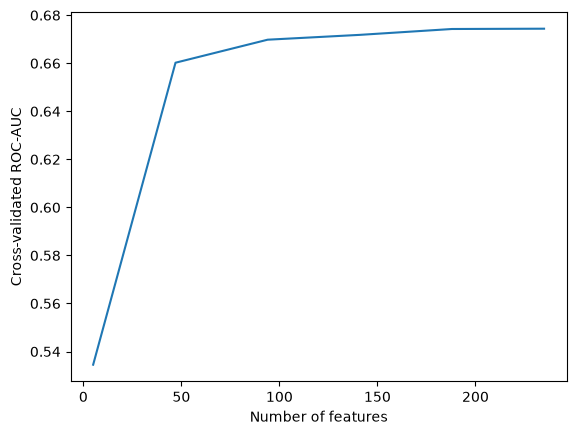

In [79]:
plt.plot(
    rfecv.cv_results_["n_features"],
    rfecv.cv_results_["mean_test_score"],
)
plt.xlabel("Number of features")
plt.ylabel("Cross-validated ROC-AUC")

In [96]:
##mapping[ 'Encoded' ]
wo_prefix_sig_features = sig_features.str.removeprefix("cat__").str.removeprefix("num__")
features_for_randomForest = mapping[ mapping[ 'Encoded' ].isin( wo_prefix_sig_features ) ]["Original"].unique()
features_for_randomForest

<StringArray>
[                    'race',                      'age',
        'admission_type_id', 'discharge_disposition_id',
      'admission_source_id',                   'diag_1',
                   'diag_2',                   'diag_3',
            'max_glu_serum',                'A1Cresult',
                'metformin',              'repaglinide',
              'glimepiride',            'acetohexamide',
                'glipizide',                'glyburide',
              'tolbutamide',             'pioglitazone',
            'rosiglitazone',                 'acarbose',
                 'miglitol',             'troglitazone',
               'tolazamide',                  'examide',
              'citoglipton',                  'insulin',
      'glyburide-metformin',      'glipizide-metformin',
 'glimepiride-pioglitazone',  'metformin-rosiglitazone',
   'metformin-pioglitazone',                   'change',
              'diabetesMed']
Length: 33, dtype: str

In [98]:
X = df[ features_for_randomForest ]
X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = labels.iloc[train_idx]
y_test = labels.iloc[test_idx]

train_groups = groups.iloc[train_idx]

In [ ]:
## using the hyperparameters identified last week
## {'classifier__bootstrap': True, 'classifier__max_depth': 10, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 5, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 200}

In [99]:
from sklearn.ensemble import RandomForestClassifier
# -------------------------------------------------
# 2. Define the model and preprocessing pipeline
# -------------------------------------------------

clf = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        bootstrap=True,
        max_depth=10,
        max_features='sqrt',
        min_samples_leaf=5, 
        min_samples_split=2, 
        n_estimators=200,
        random_state=42,
        n_jobs=1,
    )),
])

clf.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['Early','Later']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](33,)","['race','age','admission_type_id',...,'metformin-pioglitazone','change', 'diabetesMed']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,33
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying

In [112]:
from sklearn.feature_selection import SelectFromModel

selector = SelectFromModel(
    estimator=clf, 
    threshold="mean",
    importance_getter="named_steps.classifier.feature_importances_",
)
selector.fit( X_train, y_train )

,"estimator estimator: objectThe base estimator from which the transformer is built.This can be both a fitted (if ``prefit`` is set to True)or a non-fitted estimator. The estimator should have a``feature_importances_`` or ``coef_`` attribute after fitting.Otherwise, the ``importance_getter`` parameter should be used.",Pipeline(step...m_state=42))])
,"threshold threshold: str or float, default=NoneThe threshold value to use for feature selection. Features whoseabsolute importance value is greater or equal are kept while the othersare discarded. If ""median"" (resp. ""mean""), then the ``threshold`` valueis the median (resp. the mean) of the feature importances. A scalingfactor (e.g., ""1.25*mean"") may also be used. If None and if theestimator has a parameter penalty set to l1, either explicitlyor implicitly (e.g, Lasso), the threshold used is 1e-5.Otherwise, ""mean"" is used by default.",'mean'
,"importance_getter importance_getter: str or callable, default='auto'If 'auto', uses the feature importance either through a ``coef_``attribute or ``feature_importances_`` attribute of estimator.Also accepts a string that specifies an attribute name/pathfor extracting feature importance (implemented with `attrgetter`).For example, give `regressor_.coef_` in case of:class:`~sklearn.compose.TransformedTargetRegressor` or`named_steps.clf.feature_importances_` in case of:class:`~sklearn.pipeline.Pipeline` with its last step named `clf`.If `callable`, overrides the default feature importance getter.The callable is passed with the fitted estimator and it shouldreturn importance for each feature... versionadded:: 0.24",'named_steps.classifier.feature_importances_'
,"prefit prefit: bool, default=FalseWhether a prefit model is expected to be passed into the constructordirectly or not.If `True`, `estimator` must be a fitted estimator.If `False`, `estimator` is fitted and updated by calling`fit` and `partial_fit`, respectively.",False
,"norm_order norm_order: non-zero int, inf, -inf, default=1Order of the norm used to filter the vectors of coefficients below``threshold`` in the case where the ``coef_`` attribute of theestimator is of dimension 2.",1
,"max_features max_features: int, callable, default=NoneThe maximum number of features to select.- If an integer, then it specifies the maximum number of features to allow.- If a callable, then it specifies how to calculate the maximum number of features allowed. The callable will receive `X` as input: `max_features(X)`.- If `None`, then all features are kept.To only select based on ``max_features``, set ``threshold=-np.inf``... versionadded:: 0.20.. versionchanged:: 1.1 `max_features` accepts a callable.",None
Name,Type,Value
"estimator_ estimator_: estimatorThe base estimator from which the transformer is built. This attributeexist only when `fit` has been called.- If `prefit=True`, it is a deep copy of `estimator`.- If `prefit=False`, it is a clone of `estimator` and fit on the data passed to `fit` or `partial_fit`.",Pipeline,Pipeline(step...m_state=42))])
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](33,)","['race','age','admission_type_id',...,'metformin-pioglitazone','change', 'diabetesMed']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 0.24,int,33
threshold_ threshold_: floatThe threshold value used for feature selection.,float64,0.000429


In [125]:
X_train_encoded = clf.named_steps["preprocessor"].transform(X_train)
X_train_encoded=pd.DataFrame.sparse.from_spmatrix(
    X_train_encoded,
    index=X_train.index,
    columns=clf.named_steps["preprocessor"].get_feature_names_out(),
)

X_train_encoded_selected_cols = X_train_encoded.columns[ selector.get_support() ]
X_train_encoded_selected_cols

Index(['cat__race_AfricanAmerican', 'cat__race_Caucasian',
       'cat__race_Hispanic', 'cat__race_Other', 'cat__race_nan',
       'cat__age_[0-10)', 'cat__age_[10-20)', 'cat__age_[20-30)',
       'cat__age_[30-40)', 'cat__age_[40-50)',
       ...
       'cat__rosiglitazone_Steady', 'cat__insulin_Down', 'cat__insulin_No',
       'cat__insulin_Steady', 'cat__insulin_Up', 'cat__glyburide-metformin_No',
       'cat__change_Ch', 'cat__change_No', 'cat__diabetesMed_No',
       'cat__diabetesMed_Yes'],
      dtype='str', length=290)

In [127]:
lr_selected_features = selected_features
rf_selected_features = X_train_encoded_selected_cols

ovp = lr_selected_features[ lr_selected_features.isin( rf_selected_features ) ]
print( "\nOverlapping features:" )
display( ovp )

lr_uniq = lr_selected_features[ ~lr_selected_features.isin( rf_selected_features ) ]
print( "\nLR Unique:" )
display( lr_uniq )

rf_uniq = rf_selected_features[ ~rf_selected_features.isin( lr_selected_features ) ]
print( "\nRF Unique:" )
display( rf_uniq )




Overlapping features:


Index(['cat__discharge_disposition_id_11', 'cat__discharge_disposition_id_13',
       'cat__diag_1_486', 'cat__discharge_disposition_id_25',
       'cat__diag_2_272', 'cat__diag_1_786', 'cat__discharge_disposition_id_1',
       'cat__diag_1_722', 'cat__diag_1_518', 'cat__diag_3_41',
       ...
       'cat__diag_1_250.41', 'cat__diag_2_250.7', 'cat__diag_3_250.6',
       'cat__discharge_disposition_id_2', 'cat__diag_1_250.6',
       'cat__diag_3_785', 'cat__discharge_disposition_id_5',
       'cat__discharge_disposition_id_28', 'cat__discharge_disposition_id_22',
       'cat__diag_1_V58'],
      dtype='str', length=162)


LR Unique:


Index(['cat__discharge_disposition_id_14', 'cat__discharge_disposition_id_23',
       'cat__diag_1_250.12', 'cat__diag_3_413', 'cat__admission_source_id_5',
       'cat__acetohexamide_No', 'cat__citoglipton_No', 'cat__examide_No',
       'cat__metformin-pioglitazone_No', 'cat__glimepiride-pioglitazone_No',
       'cat__metformin-rosiglitazone_No', 'cat__diag_1_250.02',
       'cat__troglitazone_No', 'cat__glipizide-metformin_No',
       'cat__diag_1_250.4', 'cat__diag_1_540', 'cat__diag_1_530',
       'cat__diag_2_486', 'cat__tolazamide_No', 'cat__diag_1_386',
       'cat__diag_3_424', 'cat__diag_3_787', 'cat__diag_1_997',
       'cat__glyburide_Down', 'cat__diag_1_780', 'cat__diag_2_518',
       'cat__diag_3_305', 'cat__diag_2_507', 'cat__diag_2_574',
       'cat__diag_3_458', 'cat__tolbutamide_No', 'cat__miglitol_No',
       'cat__diag_3_715', 'cat__diag_1_724', 'cat__diag_1_590',
       'cat__diag_1_535', 'cat__diag_2_41', 'cat__diag_1_648',
       'cat__diag_1_250.22', 'cat__diag_2


RF Unique:


Index(['cat__race_AfricanAmerican', 'cat__race_Hispanic', 'cat__age_[30-40)',
       'cat__age_[40-50)', 'cat__admission_type_id_2',
       'cat__discharge_disposition_id_7', 'cat__discharge_disposition_id_9',
       'cat__admission_source_id_6', 'cat__admission_source_id_7',
       'cat__diag_1_112',
       ...
       'cat__repaglinide_Steady', 'cat__repaglinide_Up',
       'cat__glimepiride_Down', 'cat__glipizide_Up', 'cat__glyburide_Steady',
       'cat__glyburide_Up', 'cat__rosiglitazone_No', 'cat__insulin_Up',
       'cat__change_No', 'cat__diabetesMed_Yes'],
      dtype='str', length=128)

In [142]:
display( rf_uniq.str.contains( "cat__diag_1" ).sum() )
display( lr_uniq.str.contains( "cat__diag_1" ).sum() )
display( ovp.str.contains( "cat__diag_1" ).sum() )

np.int64(38)

np.int64(25)

np.int64(38)

#### Observations:
* There were:
    * 162 features shared by both learners
    * 128 features unique to RF
    *  73 features unique to LR
* Both used one-hot-encoded features from the diag* features. For example, of the diag_1_* features:
    * 38 shared
    * 38 unique to RF
    * 25 unique to LR 
* None of the numbered features (e.g. number_outpatient, number_inpatient) were selected by the RF
    * -> maybe some sort of discretization would help?
* RF included a number of medication features that were unique to it
* LR included only a few medication features, and those that it included were combinatorial features, e.g. "metformin-pioglitazone"

### Compare the performance using the different feature sets

In [150]:
drop_cols = [ 'encounter_id', 'patient_nbr', 'payer_code', 'medical_specialty', 'readmitted', 'weight', 'readmit_30_label' ]
X = df[ df.columns[~df.columns.isin( drop_cols ) ] ]
y = df[ "readmit_30_label" ]

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = labels.iloc[train_idx]
y_test = labels.iloc[test_idx]

train_groups = groups.iloc[train_idx]

X_train_encoded = preprocessor.transform(X_train)
X_train_encoded=pd.DataFrame.sparse.from_spmatrix(
    X_train_encoded,
    index=X_train.index,
    columns=preprocessor.get_feature_names_out(),
)

X_test_encoded = preprocessor.transform(X_test)
X_test_encoded=pd.DataFrame.sparse.from_spmatrix(
    X_test_encoded,
    index=X_test.index,
    columns=preprocessor.get_feature_names_out(),
)




In [154]:
## first, establish the performance of each method when using the optimal set of features
X_train_lr = X_train_encoded[ lr_selected_features ]
X_test_lr = X_test_encoded[ lr_selected_features ]
lr_clf_rfecv = LogisticRegression( 
    solver="saga",
    max_iter=5000,
    tol=1e-3,
    random_state=42,
    C=0.1,
    l1_ratio=0.5,
)

lr_clf_rfecv.fit( 
    X_train_lr, 
    y_train,
)
# -------------------------------------------------
# 6. Evaluate on the untouched 20% test set
# -------------------------------------------------

test_probabilities = lr_clf_rfecv.predict_proba(X_test_lr)[:, 1]

test_auc = roc_auc_score(y_test, test_probabilities)

print("Test AUC:", test_auc)


Test AUC: 0.6718071970841752


In [158]:
## first, establish the performance of each method when using the optimal set of features
X_train_lr = X_train_encoded[ ovp ]
X_test_lr = X_test_encoded[ ovp ]
lr_clf_rfecv = LogisticRegression( 
    solver="saga",
    max_iter=5000,
    tol=1e-3,
    random_state=42,
    C=0.1,
    l1_ratio=0.5,
)

lr_clf_rfecv.fit( 
    X_train_lr, 
    y_train,
)
# -------------------------------------------------
# 6. Evaluate on the untouched 20% test set
# -------------------------------------------------

test_probabilities = lr_clf_rfecv.predict_proba(X_test_lr)[:, 1]

test_auc = roc_auc_score(y_test, test_probabilities)

print("Test AUC:", test_auc)


Test AUC: 0.6315605132565106


#### Now, do the same with RandomForest

In [156]:
## first, establish the performance of each method when using the optimal set of features
X_train_rf = X_train_encoded[ rf_selected_features ]
X_test_rf = X_test_encoded[ rf_selected_features ]
rf_clf_rfecv = RandomForestClassifier(
        bootstrap=True,
        max_depth=10,
        max_features='sqrt',
        min_samples_leaf=5, 
        min_samples_split=2, 
        n_estimators=200,
        random_state=42,
        n_jobs=1,
    )

rf_clf_rfecv.fit( 
    X_train_rf, 
    y_train,
)
# -------------------------------------------------
# 6. Evaluate on the untouched 20% test set
# -------------------------------------------------

test_probabilities = rf_clf_rfecv.predict_proba(X_test_rf)[:, 1]

test_auc = roc_auc_score(y_test, test_probabilities)

print("Test AUC:", test_auc)


Test AUC: 0.6261833075379608


In [159]:
## first, establish the performance of each method when using the optimal set of features
X_train_rf = X_train_encoded[ ovp ]
X_test_rf = X_test_encoded[ ovp ]
rf_clf_rfecv = RandomForestClassifier(
        bootstrap=True,
        max_depth=10,
        max_features='sqrt',
        min_samples_leaf=5, 
        min_samples_split=2, 
        n_estimators=200,
        random_state=42,
        n_jobs=1,
    )

rf_clf_rfecv.fit( 
    X_train_rf, 
    y_train,
)
# -------------------------------------------------
# 6. Evaluate on the untouched 20% test set
# -------------------------------------------------

test_probabilities = rf_clf_rfecv.predict_proba(X_test_rf)[:, 1]

test_auc = roc_auc_score(y_test, test_probabilities)

print("Test AUC:", test_auc)


Test AUC: 0.6217133902713927


In [157]:
## first, establish the performance of each method when using the optimal set of features
X_train_rf = X_train_encoded[ lr_selected_features ]
X_test_rf = X_test_encoded[ lr_selected_features ]
rf_clf_rfecv = RandomForestClassifier(
        bootstrap=True,
        max_depth=10,
        max_features='sqrt',
        min_samples_leaf=5, 
        min_samples_split=2, 
        n_estimators=200,
        random_state=42,
        n_jobs=1,
    )

rf_clf_rfecv.fit( 
    X_train_rf, 
    y_train,
)
# -------------------------------------------------
# 6. Evaluate on the untouched 20% test set
# -------------------------------------------------

test_probabilities = rf_clf_rfecv.predict_proba(X_test_rf)[:, 1]

test_auc = roc_auc_score(y_test, test_probabilities)

print("Test AUC:", test_auc)


Test AUC: 0.6697643345417044


### Conclusion:
* RandomForest actually does better with the features from RFECV with LogisticRegression. Odd, but interesting.

## Using Gradient Boosting with HistGradientBoostingClassifier to solve the problem

In [166]:
from sklearn.ensemble import HistGradientBoostingClassifier
# -------------------------------------------------
# 1. Use the set of features that were most predictive - and which were fed into the randomForestClassifier
# -------------------------------------------------
X = df[ features_for_randomForest ]
X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = labels.iloc[train_idx]
y_test = labels.iloc[test_idx]

train_groups = groups.iloc[train_idx]

# -------------------------------------------------
# 2. Define the model and preprocessing pipeline
# -------------------------------------------------

hgb_preprocessor = clone(preprocessor)
hgb_preprocessor.set_params(cat__encoder__sparse_output=False)

hgb_clf = Pipeline([
    ("preprocessor", hgb_preprocessor),
    ("classifier", HistGradientBoostingClassifier (
        max_bins=255,
        early_stopping=False,
        random_state=42 ) )
])


# -------------------------------------------------
# 3. Define which hyperparameters to evaluate
# -------------------------------------------------

param_grid = {
    "classifier__max_iter": [100, 200],
    "classifier__learning_rate": [0.02, 0.05, 0.1],
    "classifier__max_leaf_nodes": [15, 31],
    "classifier__min_samples_leaf": [20, 50],
    "classifier__l2_regularization": [0.0, 1.0],
}


# -------------------------------------------------
# 4. Perform CV and select the best hyperparameters
# -------------------------------------------------

inner_cv = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=123
)

hgb_grid = GridSearchCV(
    estimator=hgb_clf,
    param_grid=param_grid,
    cv=inner_cv,
    scoring="roc_auc",
    refit=True,
    verbose=3,
    n_jobs=5 
)

hgb_grid.fit(X_train, y_train, groups=train_groups)


# -------------------------------------------------
# 5. Retrieve the selected configuration
# -------------------------------------------------

print(hgb_grid.best_params_)
print(hgb_grid.best_score_)

hgb_final_clf = hgb_grid.best_estimator_


# -------------------------------------------------
# 6. Evaluate on the untouched 20% test set
# -------------------------------------------------

test_probabilities = hgb_final_clf.predict_proba(X_test)[:, 1]

test_auc = roc_auc_score(y_test, test_probabilities)

print("Test AUC:", test_auc)


Fitting 5 folds for each of 48 candidates, totalling 240 fits
[CV 2/5] END classifier__l2_regularization=0.0, classifier__learning_rate=0.02, classifier__max_iter=100, classifier__max_leaf_nodes=15, classifier__min_samples_leaf=20;, score=0.621 total time=  59.3s
[CV 4/5] END classifier__l2_regularization=0.0, classifier__learning_rate=0.02, classifier__max_iter=100, classifier__max_leaf_nodes=15, classifier__min_samples_leaf=50;, score=0.627 total time= 1.0min
[CV 4/5] END classifier__l2_regularization=0.0, classifier__learning_rate=0.02, classifier__max_iter=100, classifier__max_leaf_nodes=31, classifier__min_samples_leaf=20;, score=0.630 total time= 1.9min
[CV 5/5] END classifier__l2_regularization=0.0, classifier__learning_rate=0.02, classifier__max_iter=100, classifier__max_leaf_nodes=31, classifier__min_samples_leaf=50;, score=0.633 total time= 1.5min
[CV 5/5] END classifier__l2_regularization=0.0, classifier__learning_rate=0.02, classifier__max_iter=200, classifier__max_leaf_nod

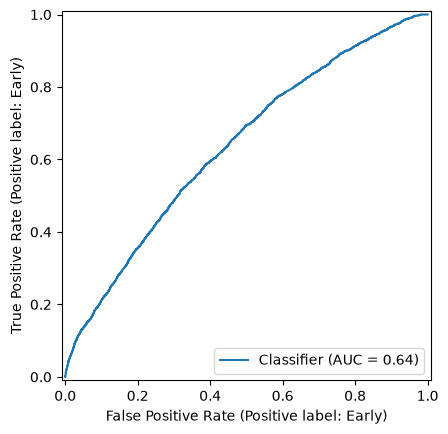

In [167]:
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

pos_idx = list(hgb_final_clf.classes_).index("Early")
y_score = hgb_final_clf.predict_proba(X_test)[:, pos_idx]
RocCurveDisplay.from_predictions(y_test, y_score, pos_label="Early")
plt.show()